<a href="https://colab.research.google.com/github/LucioFassarella/SQC/blob/main/SQC_povm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum simulation of a positive operator-valued measure


1-qubit state space:
$$\mathcal{H} \equiv \mathbb{C}^2 = \mathrm{spam}\left\{\vert 0\rangle, \vert 1\rangle \right\}.
$$

Positive operator-valued measure:
$$
\begin{split}
M &= \left\{ M_0, M_1\right\};\\
M_0 &= \frac{1}{2\sqrt{2}}\left(\vert 0 \rangle\langle 0 \vert + \sqrt{3}\vert 1 \rangle\langle 0 \vert + 2\vert 1 \rangle\langle 1 \vert\right),\\
M_1 &= \frac{1}{2\sqrt{2}}\left(\vert 0 \rangle\langle 0 \vert - \sqrt{3}\vert 1 \rangle\langle 0 \vert + 2\vert 1 \rangle\langle 1 \vert\right).
\end{split}
$$

$\ $
The Stinespring dilation of the associated quantum channel:
$$
V: \mathcal{H}\rightarrow \mathcal{H}\otimes\mathcal{Q}_1,\ \ V \vert \psi \rangle = M_0 \vert \psi \rangle\otimes \vert 0\rangle + M_1 \vert \psi \rangle\otimes \vert 1\rangle.
$$

$\ $
The primary auxiliary state and corresponding Stinespring unitary:
$\ $
$$
\begin{split}
&W: \mathcal{H}\otimes\mathcal{Q}_1\rightarrow \mathcal{H}\otimes\mathcal{Q}_1,\ \ W \vert j,k \rangle = \vert \phi_{jk} \rangle \ \left(j,k = 0, 1\right);\\
& \vert \phi_{00}\rangle = V\vert 00\rangle =\frac{1}{2\sqrt{2}}\left(\vert 00\rangle + \sqrt{3}\vert 10 \rangle + \vert 01\rangle - \sqrt{3}\vert 11\rangle \right),\\
& \vert \phi_{10}\rangle = V\vert 10\rangle = \frac{1}{\sqrt{2}}\left(\vert 10\rangle +\vert 11\rangle \right),\\
& \vert \phi_{01}\rangle = \frac{1}{\sqrt{2}}\left(\vert 00\rangle - \vert 01\rangle \right),\\
& \vert \phi_{11}\rangle = \frac{1}{2\sqrt{2}} \left(\sqrt{3}\vert 00\rangle - \vert 10\rangle + \sqrt{3} \vert 01\rangle + \vert 11\rangle \right).
\end{split}
$$

$\ $
The $W$ matrix in the computational basis, calculated below with *Sympy*:
$$
\left\lbrack W \right\rbrack = \begin{bmatrix}
\frac{1}{2\sqrt{2}} & 0 & \frac{1}{2\sqrt{2}} & \frac{\sqrt{3}}{2\sqrt{2}}\\
      \frac{\sqrt{3}}{2\sqrt{2}} & \frac{1}{2\sqrt{2}} & 0 & -\frac{1}{2\sqrt{2}}\\
      \frac{1}{2\sqrt{2}} & 0 & -\frac{1}{2\sqrt{2}} & \frac{\sqrt{3}}{2\sqrt{2}}\\
      -\frac{\sqrt{3}}{2\sqrt{2}} & \frac{1}{2\sqrt{2}}& 0 & \frac{1}{2\sqrt{2}}
\end{bmatrix}.
$$

$\ $
For the state
$$
\vert + \rangle =\frac{\vert 0 \rangle + \vert 1 \rangle}{2} = H\vert 0 \rangle,
$$

we calculate analiticaly the following probabilities:
$$
\mathrm{Pr}(M_1 \vert +) = tr(M_2 \vert + \rangle\langle + \vert M_2^\dagger) = \frac{1}{2} + \frac{\sqrt{3}}{4} \approx 0,933012702;
$$
$$
\mathrm{Pr}(M_2 \vert +) = tr(M_2 \vert + \rangle\langle + \vert M_2^\dagger) = \frac{1}{2} - \frac{\sqrt{3}}{4} \approx 0,066987298.
$$

## Analytical calculations in Sympy

In [2]:
import sympy as sp

# Quantum probability function
def Pr(meas_operator, estate):
    return (meas_operator * estate * meas_operator.H).trace()

# Measurement operators
M_0 = (1 / (2 * sp.sqrt(2))) * sp.Matrix([
    [1, 0],
    [sp.sqrt(3), 2]
])

M_1 = (1 / (2 * sp.sqrt(2))) * sp.Matrix([
    [1, 0],
    [-sp.sqrt(3), 2]
])

print("Kraus operator M_0:")
display(M_0)
print("\nKraus operator M_1:")
display(M_1)

# Checking the completeness relation: M_0^dagger * M_0 + M_1^dagger * M_1 = I
completeness = M_0.H * M_0 + M_1.H * M_1
print("\nCompleteness relation (M_0^H * M_0 + M_1^H * M_1):")
display(sp.simplify(completeness))

# State
rho = (1/2)*sp.Matrix([
    [1, 1],
    [1, 1]
])
print("Quantum state rho:")
display(rho)

# Quantum channel action
rho_after_channel = M_0 * rho * M_0.H + M_1 * rho * M_1.H
print("\nQuantum state after quantum channel action:")
display(rho_after_channel)
display(sp.simplify(rho_after_channel))

# Probabilities
print("Probability of '0':")
display(Pr(M_0, rho))
display(sp.simplify(Pr(M_0,rho)))
display(sp.simplify(Pr(M_0,rho)).evalf())
print("\nProbability of '1':")
display(Pr(M_1, rho))
display(sp.simplify(Pr(M_1,rho)))
display(sp.simplify(Pr(M_1,rho)).evalf())

Kraus operator M_0:


Matrix([
[sqrt(2)/4,         0],
[sqrt(6)/4, sqrt(2)/2]])


Kraus operator M_1:


Matrix([
[ sqrt(2)/4,         0],
[-sqrt(6)/4, sqrt(2)/2]])


Completeness relation (M_0^H * M_0 + M_1^H * M_1):


...

0.933012701892219


Probability of '1':


-sqrt(6)*(-0.125*sqrt(6) + 0.25*sqrt(2))/4 + sqrt(2)*(-0.125*sqrt(6) + 0.25*sqrt(2))/2 + 0.0625

0.5 - 0.25*sqrt(3)

0.0669872981077807

# Simulation

In [4]:
'''
Qiskit installation
'''

!pip install qiskit -U
!pip install qiskit_aer -U
!pip install qiskit-ibm-runtime -U

!pip install matplotlib
!pip install pylatexenc

import qiskit
qiskit.__version__

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.6 MB/s eta 0:00:00


'2.5.2'

In [7]:
'''
Texlive installation to print the quantum circuit
'''

!apt-get update && apt-get install -y texlive-latex-extra texlive-pictures poppler-utils

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.3 MB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,546 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,183 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [52.1 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3

In [6]:
# Stinespring unitary

import numpy as np

W = np.array([
      [1/(2*np.sqrt(2)), 0, 1/np.sqrt(2), np.sqrt(3)/(2*np.sqrt(2))],
      [np.sqrt(3)/(2*np.sqrt(2)), 1/np.sqrt(2), 0, -1/(2*np.sqrt(2))],
      [1/(2*np.sqrt(2)), 0, -1/np.sqrt(2), np.sqrt(3)/(2*np.sqrt(2))],
      [-np.sqrt(3)/(2*np.sqrt(2)), 1/np.sqrt(2), 0, 1/(2*np.sqrt(2))]
])

print("W")
display(W)

#print("W*")
W_dagger = W.conj().T

# Unitarity test
identity_test_1 = np.round(W @ W_dagger, 10)
identity_test_2 = np.round(W_dagger @ W, 10)

unitario_quest = np.allclose(W @ W_dagger, np.eye(W.shape[0]))
print(f"Is W unitary? {unitario_quest}!")

W


array([[ 0.35355339,  0.        ,  0.70710678,  0.61237244],
       [ 0.61237244,  0.70710678,  0.        , -0.35355339],
       [ 0.35355339,  0.        , -0.70710678,  0.61237244],
       [-0.61237244,  0.70710678,  0.        ,  0.35355339]])

Is W unitary? True!


Quantum Circuit with Mid-Circuit Measurement and Reset:


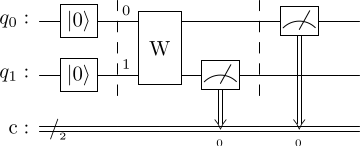


Simulation Results:
{'01': 24627, '00': 8141}
Probability of M_0:


0.248443603515625

Probability of M_1:


0.751556396484375

In [29]:
'''
Quantum channel action
'''

# Methods
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator

# Quantum circuit and registers
qr = QuantumRegister(2, name="q")
cr = ClassicalRegister(2, name="c")
qc = QuantumCircuit(qr, cr)

# Preparation of the state |+ >
qc.reset(qr[0])
qc.reset(qr[1])
qc.barrier()

# Stinespring's unitary
from qiskit.quantum_info import Operator # Optional method (not used here)

W_operator = Operator(W)
qc.unitary(W_operator, [0, 1], label='W') # To print with "mpl": label = r'$W_\rho$'

# Partial measurement of auxiliar qubit and recycling
qc.measure(qr[1], cr[0])
qc.barrier()

# Final measurement of the qubits
qc.measure(qr[0], cr[0])

# Draw the circuit
print("Quantum Circuit with Mid-Circuit Measurement and Reset:")
display(qc.draw("latex"))

# Simulation
simulator = AerSimulator()
shots = 2**15
job = simulator.run(qc, shots=shots)
result = job.result()

# Printing results
counts = result.get_counts(qc)
print("\nSimulation Results:")
print(counts)

print("Probability of M_0:")
display(counts['00']/shots)
print("Probability of M_1:")
display(counts['01']/shots)

Quantum Circuit with Mid-Circuit Measurement and Reset:


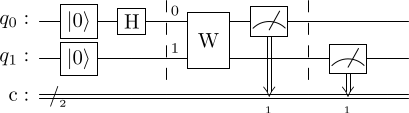


Simulation Results:
{'10': 2168, '00': 30600}
Probability of M_0:


0.933837890625

Probability of M_1:


0.066162109375

In [26]:
'''
Measurement probabilities
'''

# Methods
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator

# Quantum circuit and registers
qr = QuantumRegister(2, name="q")
cr = ClassicalRegister(2, name="c")
qc = QuantumCircuit(qr, cr)

# Preparation of the quantum state |+ >
qc.reset(qr[0])
qc.reset(qr[1])
qc.h(0)
qc.barrier()

# Stinespring's unitary
from qiskit.quantum_info import Operator # Optional method (not used here)

W_operator = Operator(W)
qc.unitary(W_operator, [0, 1], label='W') # To print with "mpl": label = r'$W_\rho$'

# Partial measurement of the systems' qubit and recycling
qc.measure(qr[0], cr[1])
qc.barrier()

# Final measurement of the auxiliar qubit
qc.measure(qr[1], cr[1])

# Draw the circuit
print("Quantum Circuit with Mid-Circuit Measurement and Reset:")
display(qc.draw("latex"))

# Simulation
simulator = AerSimulator()
shots = 2**15
job = simulator.run(qc, shots=shots)
result = job.result()
counts = result.get_counts(qc)
print("\nSimulation Results:")
print(counts)

# Pós-processing

print("Probability of M_0:")
display(counts['00']/shots)
print("Probability of M_1:")
display(counts['10']/shots)